## LSTM Example

We want to train an univariate, one feature LSTM

**0) Loading Libraries and Subroutines**

First, we call the standard libraries for plotting and numerical operations

In [3]:
import numpy as np
import matplotlib.pyplot as plt

and next all LSTM related keras libraries:

In [4]:
from keras import optimizers
from keras.layers import LSTM
from keras.layers import Dense
from keras.models import Sequential
from sklearn.preprocessing import MinMaxScaler

As shown in the lecture, the LSTM needs a certain shape of the data if we want to predict certain number of steps in the future using a certain number of steps from the past. Therfore, we are defining a subroutine that puts the data set in the correct shape for our LSTM (see also later).

In [1]:
def prepare_data(data, n_past, n_future):
    n_samples = len(data) - n_past - n_future + 1
    
    x = np.empty((n_samples, n_past) + data.shape[1:], dtype=data.dtype)
    y = np.empty((n_samples, n_future) + data.shape[1:], dtype=data.dtype)
    
    for i in range(n_samples):
        x[i] = data[i : i + n_past]
        y[i] = data[i + n_past : i + n_past + n_future]
    
    return x, y

<br>

**1) Generating a Simple Dataset**

For now, we want to keep it simple and create an artificial dataset in order to focus on the LSTM itself.

In [5]:
t_start = -50
t_end   = 10
incr    = 0.25

t       = np.arange(t_start, t_end, incr)
t       = t.reshape(len(t), 1)
Y_t     = np.sin(t) + 0.1*np.random.randn(len(t), 1) + np.exp((t + 20)*0.05) #adding noise

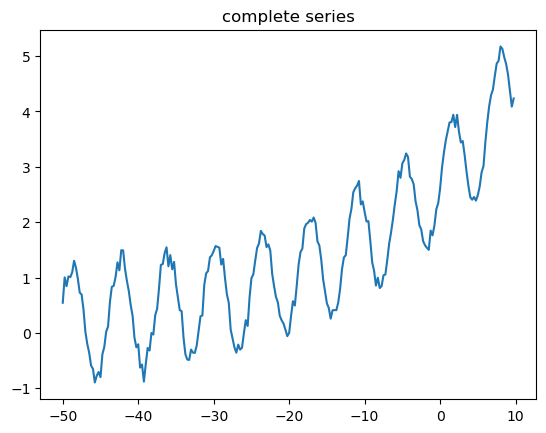

In [6]:
plt.plot(t, Y_t)
plt.title('complete series')
plt.show()

**2) Preprocessing the Data**

2a) As usual, we normalize the data:

In [8]:
scaler  = MinMaxScaler(feature_range = (0, 1))
Y_tnorm = scaler.fit_transform(Y_t)

2b) Reshaping the Data

The dataset has only one feature. We want to predict ```dt_futu``` data points into the future and train the LSTM with the previous ```dt_past``` time steps to predict the next. For that purpose, we need to reshape the data in such a way that ```dt_futu``` is interpreted as features. Therefore, we run the subroutine ```prepare_data``` we defined earlier<br>
<br>

In [9]:
dt_past    = 20
dt_futu    = 8
n_features = 1

In [10]:
[X, Y] = prepare_data(Y_tnorm, dt_past, dt_futu)

<br>

Let us check the shapes:

In [11]:
print(Y_tnorm.shape)
print(X.shape)
print(Y.shape)

(240, 1)
(213, 20, 1)
(213, 8, 1)


In order to train the LSTM with $dt_{futu}$ and $dt_{past}$, we need the first $dt_{past}$ steps in order to train for the next prediction. The length of the period we want to predict is $dt_{futu}$. The last step in the training will be the point, when we predict the last sequence $dt_{futu}$ with the previous steps $dt_{past}$. Thus, the training data set has the length $len\left(Y_{tnorm}\right) - dt_{past} - dt_{futu} + 1$. Each time point in the past we need for the prediction will have its own influence on the future and therefore are regarded as feature. Thus, $X$ has to have the shape $\left[len\left(Y_{tnorm}\right) - dt_{past} - dt_{futu} + 1\right] \times dt_{past}$.<br>   
Because of that interpretation, each feature is shifted by one time point:

In [15]:
print(X[:10, :5, 0])

[[0.23727976 0.3127756  0.28660911 0.31564089 0.31353849]
 [0.3127756  0.28660911 0.31564089 0.31353849 0.32794896]
 [0.28660911 0.31564089 0.31353849 0.32794896 0.36226984]
 [0.31564089 0.31353849 0.32794896 0.36226984 0.34156463]
 [0.31353849 0.32794896 0.36226984 0.34156463 0.30834574]
 [0.32794896 0.36226984 0.34156463 0.30834574 0.26747778]
 [0.36226984 0.34156463 0.30834574 0.26747778 0.26159009]
 [0.34156463 0.30834574 0.26747778 0.26159009 0.21619208]
 [0.30834574 0.26747778 0.26159009 0.21619208 0.15023165]
 [0.26747778 0.26159009 0.21619208 0.15023165 0.11443369]]


<br>

Following the same logic, in order to train the LSTM to predict the future $dt_{futu}$ ahead, $Y$ needs to have the same structure: 

In [16]:
print(Y[:10, :5, 0])

[[0.01591631 0.08400187 0.10547806 0.15092104 0.16636576]
 [0.08400187 0.10547806 0.15092104 0.16636576 0.23985091]
 [0.10547806 0.15092104 0.16636576 0.23985091 0.28463724]
 [0.15092104 0.16636576 0.23985091 0.28463724 0.28764883]
 [0.16636576 0.23985091 0.28463724 0.28764883 0.31426283]
 [0.23985091 0.28463724 0.28764883 0.31426283 0.35762263]
 [0.28463724 0.28764883 0.31426283 0.35762263 0.33376338]
 [0.28764883 0.31426283 0.35762263 0.33376338 0.39381122]
 [0.31426283 0.35762263 0.33376338 0.39381122 0.39306725]
 [0.35762263 0.33376338 0.39381122 0.39306725 0.3380543 ]]


<br>

2c) Splitting data into Training and Test dataset
We split the data into 70% training and 30% test set manually.

In [20]:
cut            = int(np.round(0.7*Y_tnorm.shape[0]))

TrainX, TrainY = X[:cut], Y[:cut]
TestX,   TestY = X[cut:], Y[cut:]

Just to make sure, that the shape is ```len(X) x dt_past x n_features```

In [13]:
print(TrainX.shape)

(168, 20, 1)


<br>

**3) Creating the Model**

Creating a LSTM in Python follows the same syntax as for CNNs. We want to predict data points in the future, based on previous data points. Therefore, we need to solve a **regression** problem:<br>

In [18]:
n_neurons  = 400

model = Sequential()
model.add(LSTM(n_neurons, input_shape = (dt_past, n_features), activation = 'tanh'))
model.add(Dense(dt_futu))

opt = optimizers.Adam()
model.compile(loss = 'mean_squared_error', optimizer = opt)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 400)            │       643,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         3,208 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 646,408 (2.47 MB)

 Trainable params: 646,408 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

<br>

**4) Running the Fit**

In [ ]:
n_epochs   = 200
batch_size = 128

out = model.fit(TrainX, TrainY, epochs = n_epochs, batch_size = batch_size, validation_split = 0.2, verbose = 2, shuffle = True)

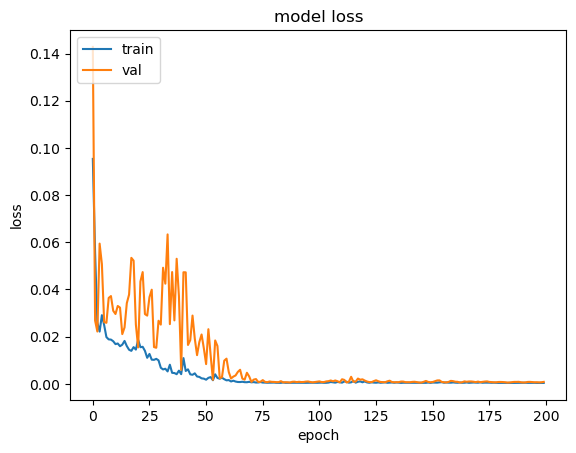

In [22]:
#plotting #############################################################
plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc = 'upper left')
plt.savefig('training loss.pdf')
plt.show()
#######################################################################

<br>

**5) Evaluating the Fit**

Next, we run the test set on the trained model and plot the prediction against the actual values.

In [23]:
PredY = model.predict(TestX)
back  = PredY.shape[0]
print(PredY.shape, TestX.shape)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
(45, 8) (45, 20, 1)


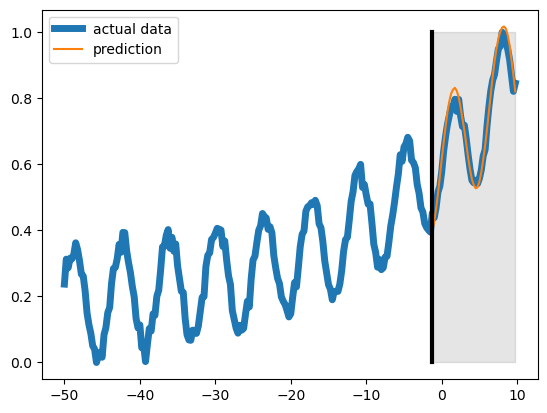

In [24]:
plt.plot(t, Y_tnorm, linewidth = 5)
plt.plot(t[-back:], PredY[:, dt_futu-1])
plt.legend(['actual data', 'prediction'])
plt.fill_between([t[-back,0], t[-1,0]], 0, 1, color = 'k', alpha = 0.1)
plt.plot([t[-back,0], t[-back,0]], [0, 1], 'k-', linewidth = 3)
plt.show()

In [25]:
PredY[:10,:5]

array([[0.4682773 , 0.43050796, 0.39989486, 0.3820666 , 0.37951773],
       [0.4390482 , 0.4042287 , 0.38284656, 0.37361676, 0.3824353 ],
       [0.41730377, 0.38747275, 0.3767543 , 0.3775851 , 0.3971587 ],
       [0.40357396, 0.3795875 , 0.37998876, 0.3912447 , 0.4222531 ],
       [0.4048935 , 0.3886553 , 0.399976  , 0.42229345, 0.461541  ],
       [0.4135019 , 0.4050938 , 0.42649218, 0.4592563 , 0.50574917],
       [0.42820624, 0.42730135, 0.45764998, 0.49986327, 0.5523425 ],
       [0.4514313 , 0.4580031 , 0.49568018, 0.54636216, 0.6022718 ],
       [0.4878063 , 0.50070155, 0.54298097, 0.5999732 , 0.65824074],
       [0.52410257, 0.5425676 , 0.5878521 , 0.64949465, 0.70668733]],
      dtype=float32)

Since the predicted values in each column of ```PredY``` refer to different sequences in the future, each shifted by one time point, we can also plot with respect to another reference point (note: for plotting the ```t``` axes needs to be shifted by the same time step!):

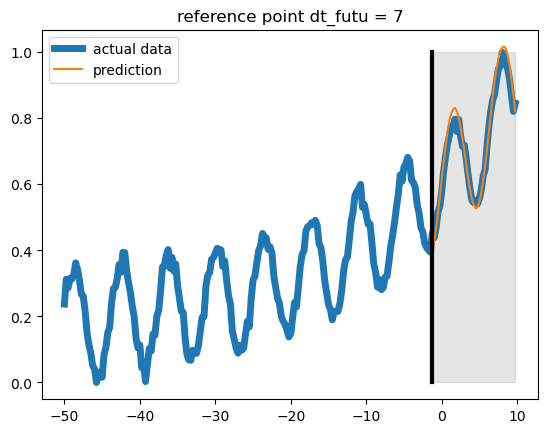

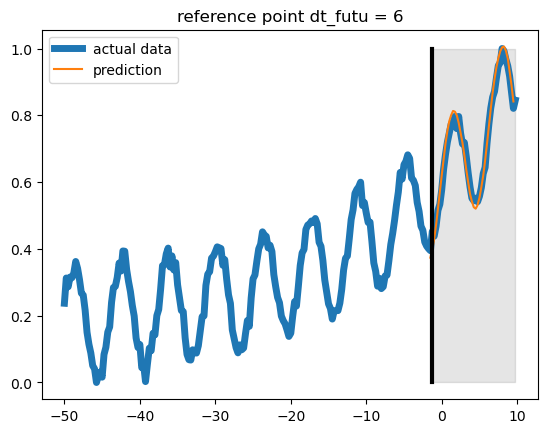

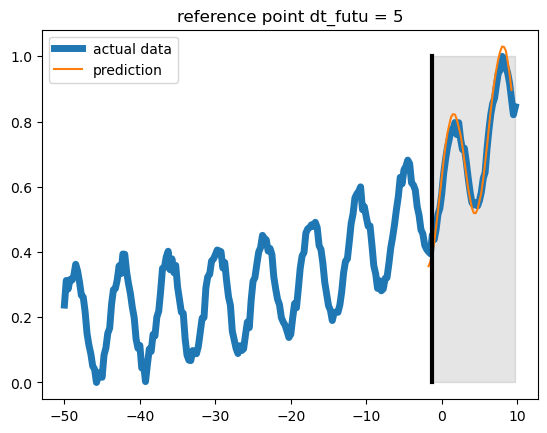

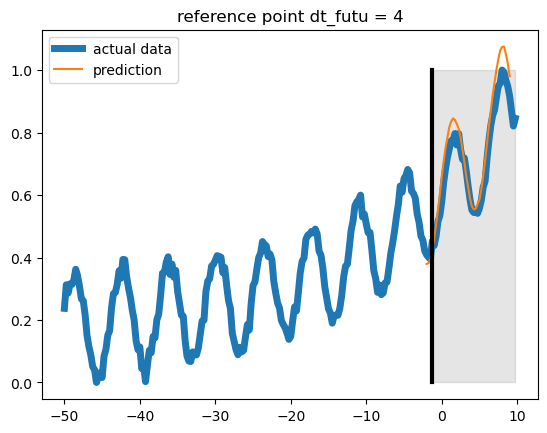

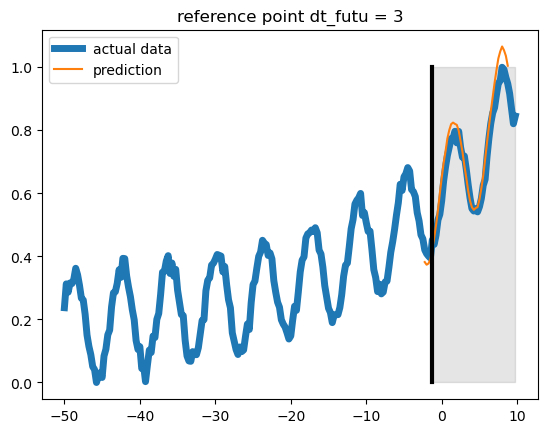

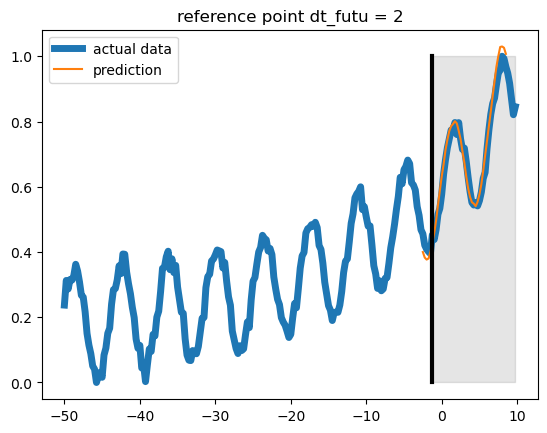

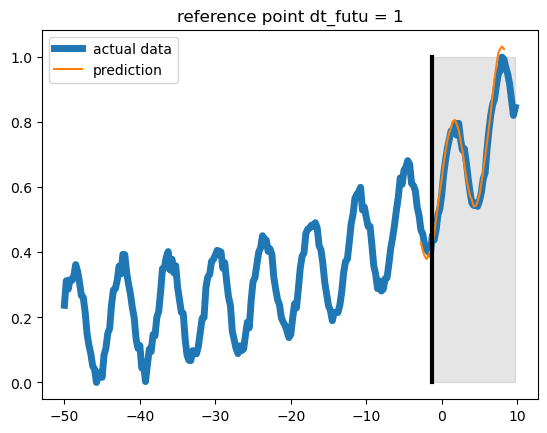

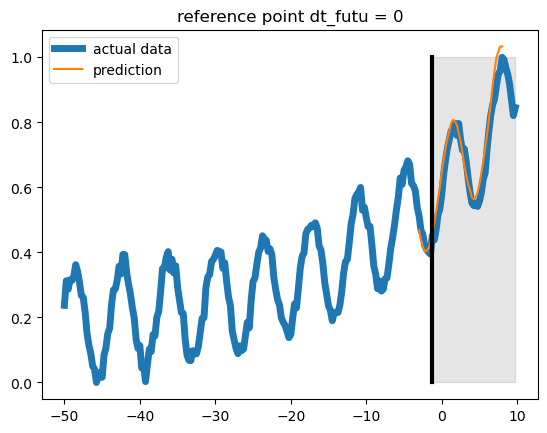

In [26]:
#dt_back = 6 #0....dt_futu

#prediction from different reference points
for dt_back in range(dt_futu):
    plt.plot(t, Y_tnorm, linewidth = 5)
    plt.plot(t[-back:] - incr*dt_back, PredY[:, dt_futu-1-dt_back])
    plt.legend(['actual data', 'prediction'])
    plt.fill_between([t[-back,0], t[-1,0]], 0, 1, color = 'k', alpha = 0.1)
    plt.plot([t[-back,0], t[-back,0]], [0, 1], 'k-', linewidth = 3)
    plt.title('reference point dt_futu = ' + str(dt_futu-1-dt_back))
    plt.show()